# Graph — Jalur Terpendek, Pohon Rentang Minimum, Rute Keliling (TSP), Sentralitas
**Kapan dipakai:** rute distribusi/logistik, jaringan jalan, penempatan gudang, kota paling
strategis.

**Langkah:**
1. Hitung jarak antar kota, bangun graf (tiap kota → `N_NEIGHBORS` kota terdekat).
2. Jalur terpendek asal → tujuan, pohon rentang minimum (MST), rute keliling semua kota (TSP).
3. Sentralitas: kota yang paling sering dilewati / paling dekat ke semua kota lain.

**Data demo:** 34 ibu kota provinsi (lat/lon). Bobot sisi = jarak garis lurus haversine (km).
Data lomba biasanya sudah berisi daftar sisi (asal, tujuan, jarak): langsung pakai di sel
**Bangun graf** dengan `graph.add_edge(asal, tujuan, distance=jarak)`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/graph"   # GANTI saat lomba
CITY_CSV = f"{DATA_FOLDER}/kota_indonesia.csv"

NAME_COL = "kota"
LAT_COL = "lat"
LON_COL = "lon"
N_NEIGHBORS = 4             # tiap kota disambung ke 4 kota terdekat
START = "Banda Aceh"
END = "Jayapura"
EARTH_RADIUS_KM = 6371
SEED = 42

## Baca data

In [3]:
cities = pd.read_csv(CITY_CSV)
missing = cities.isna().sum()
print(cities.shape, "| missing:", missing.sum())
cities.head()

(34, 3) | missing: 0


,kota,lat,lon
0,Banda Aceh,5.55,95.32
1,Medan,3.59,98.67
2,Padang,-0.95,100.35
3,Pekanbaru,0.51,101.45
4,Jambi,-1.61,103.61


## Jarak haversine semua pasangan kota (km)
Haversine = jarak di permukaan bola bumi, bukan jarak lurus pada angka lat/lon.

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lat2 = np.radians(lat2)
    lat_change = lat2 - lat1
    lon_change = np.radians(lon2 - lon1)
    part = np.sin(lat_change / 2) ** 2
    part = part + np.cos(lat1) * np.cos(lat2) * np.sin(lon_change / 2) ** 2
    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(part))


names = list(cities[NAME_COL])
distance = pd.DataFrame(0.0, index=names, columns=names)   # tabel jarak kota x kota
for i in range(len(cities)):
    for other in range(len(cities)):
        distance.iloc[i, other] = haversine_km(cities[LAT_COL][i], cities[LON_COL][i],
                                               cities[LAT_COL][other], cities[LON_COL][other])
print("contoh jarak Jakarta–Surabaya:", round(distance.loc["Jakarta", "Surabaya"]), "km")

contoh jarak Jakarta–Surabaya: 662 km


## Bangun graf: tiap kota → K kota terdekat

34 simpul, 88 sisi
semua kota terhubung: True


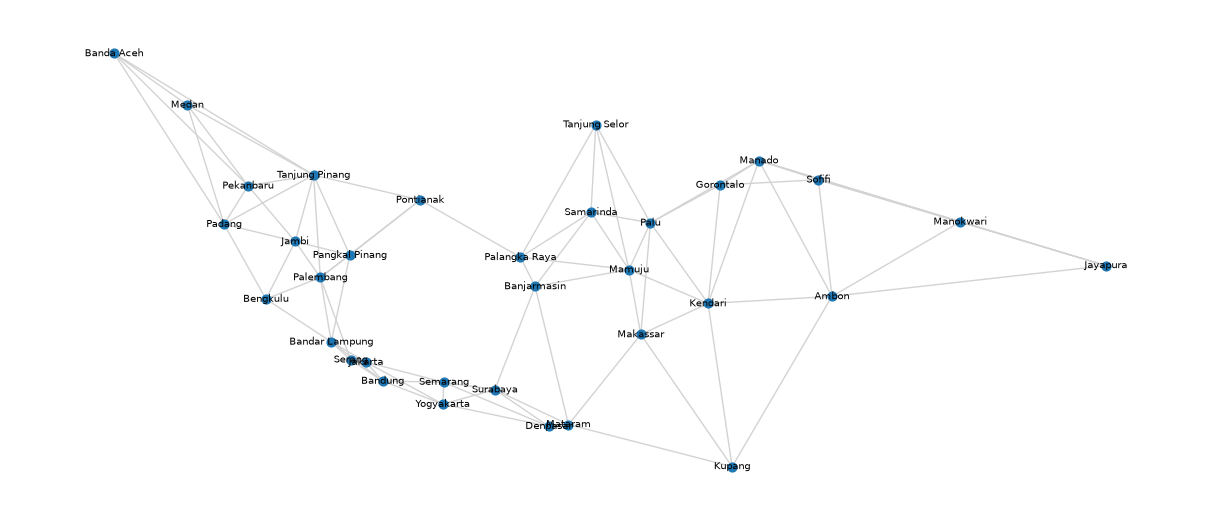

In [5]:
graph = nx.Graph()
for name in names:
    others = distance.loc[name].drop(name)       # jarak ke semua kota lain
    nearest = others.nsmallest(N_NEIGHBORS)
    for neighbor in nearest.index:
        graph.add_edge(name, neighbor, distance=round(nearest[neighbor], 1))

positions = {}                                   # posisi gambar = (lon, lat)
for name, lon, lat in zip(cities[NAME_COL], cities[LON_COL], cities[LAT_COL]):
    positions[name] = (lon, lat)
print(graph.number_of_nodes(), "simpul,", graph.number_of_edges(), "sisi")
print("semua kota terhubung:", nx.is_connected(graph))
plt.figure(figsize=(12, 5))
nx.draw(graph, positions, with_labels=True, node_size=40, font_size=7, edge_color="lightgray")
plt.show()

## Jalur terpendek
Pilih SATU algoritma: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.
A* memakai perkiraan jarak garis lurus ke tujuan → lebih cepat di graf besar, hasil sama.

In [6]:
def straight_distance(city_a, city_b):
    return distance.loc[city_a, city_b]


path = nx.dijkstra_path(graph, START, END, weight="distance")
# path = nx.astar_path(graph, START, END, heuristic=straight_distance, weight="distance")
# path = nx.bellman_ford_path(graph, START, END, weight="distance")   # bobot boleh negatif
# path = nx.shortest_path(graph, START, END)      # paling sedikit lompatan, tanpa bobot

path_length = nx.path_weight(graph, path, weight="distance")
print(" → ".join(path))
print(f"panjang jalur: {path_length:.0f} km")
print(f"garis lurus  : {straight_distance(START, END):.0f} km")

Banda Aceh → Tanjung Pinang → Pontianak → Palangka Raya → Mamuju → Kendari → Ambon → Jayapura
panjang jalur: 5264 km
garis lurus  : 5122 km


## Pohon rentang minimum (MST): jaringan termurah yang menghubungkan semua kota

In [7]:
mst = nx.minimum_spanning_tree(graph, weight="distance")
print("total panjang MST:", round(mst.size(weight="distance")), "km")
print("jumlah sisi MST:", mst.number_of_edges())

total panjang MST: 10685 km
jumlah sisi MST: 33


## Rute keliling semua kota (TSP, aproksimasi)
Dihitung di graf lengkap (semua kota tersambung langsung).
Pilih SATU metode: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [8]:
complete = nx.complete_graph(names)
for city_a, city_b in complete.edges:
    complete[city_a][city_b]["distance"] = distance.loc[city_a, city_b]
tsp = nx.approximation.traveling_salesman_problem
route = tsp(complete, weight="distance", method=nx.approximation.christofides)
# route = tsp(complete, weight="distance", method=nx.approximation.greedy_tsp)   # paling cepat
# route = tsp(complete, weight="distance", method=nx.approximation.simulated_annealing_tsp,
#             init_cycle="greedy", seed=SEED)        # lebih lambat, sering lebih pendek
print("panjang rute keliling:", round(nx.path_weight(complete, route, weight="distance")), "km")

panjang rute keliling: 15367 km


## Gambar: MST + jalur terpendek, dan rute keliling

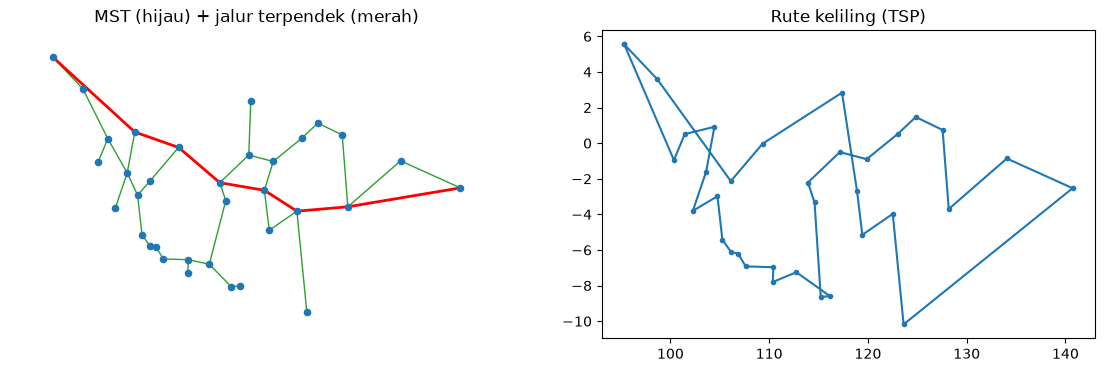

In [9]:
route_lon = []
route_lat = []
for name in route:
    route_lon.append(positions[name][0])
    route_lat.append(positions[name][1])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
nx.draw(mst, positions, ax=axes[0], node_size=20, edge_color="tab:green")
nx.draw_networkx_edges(graph.subgraph(path), positions, ax=axes[0], edge_color="red", width=2)
axes[0].set_title("MST (hijau) + jalur terpendek (merah)")
axes[1].plot(route_lon, route_lat, "-o", markersize=3)
axes[1].set_title("Rute keliling (TSP)")
plt.show()

## Sentralitas: kota paling strategis
- **betweenness** = seberapa sering kota dilewati jalur terpendek antar kota lain.
- **mean_distance_km** = 1 / closeness = rata-rata jarak jalur ke semua kota lain
  (kecil = pusat, cocok untuk gudang).

In [10]:
betweenness = nx.betweenness_centrality(graph, weight="distance")
closeness = nx.closeness_centrality(graph, distance="distance")
centrality = pd.DataFrame(index=list(graph.nodes))
centrality["degree"] = pd.Series(dict(graph.degree()))
centrality["betweenness"] = pd.Series(betweenness)
centrality["mean_distance_km"] = 1 / pd.Series(closeness)
ranking = centrality.sort_values("betweenness", ascending=False)
ranking.head(8).round(3)

,degree,betweenness,mean_distance_km
Palangka Raya,5,0.258,1206.906
Pontianak,4,0.244,1334.261
Mamuju,7,0.189,1299.927
Surabaya,5,0.184,1270.515
Semarang,5,0.184,1302.658
Jakarta,5,0.165,1380.252
Kendari,7,0.153,1499.427
Palu,7,0.142,1399.591


## Simpan hasil (urutan rute keliling + betweenness)

In [11]:
result = pd.DataFrame()
result["order"] = np.arange(len(route))
result["city"] = route
result["betweenness"] = result["city"].map(betweenness)
result.to_csv("hasil.csv", index=False)
result.head()

,order,city,betweenness
0,0,Banda Aceh,0.000000
1,1,Padang,0.024621
2,2,Pekanbaru,0.030303
3,3,Tanjung Pinang,0.113636
4,4,Jambi,0.054924
